# Week 5 · Inside the mystery 8
## What do the layers learn?

In section, a few chosen white pixels made a network stop saying “8.” Here you can train a small network, look inside its layers, and see how changing pixels changes its answer.

All code is supplied. Start by running it and reading the pictures. Then try a different digit or hidden neuron.

### Open and run
1. Open the notebook in **Google Colab** and sign in.
2. Choose **File → Save a copy in Drive** to keep your experiments.
3. Choose **Runtime → Run all**, or run the cells from top to bottom. A CPU is enough; no local installation or GPU is needed.
4. Wait for the training cell to finish before exploring the layers. Training time depends on the runtime. Saved outputs let you read the notebook before running it.

The notebook uses local MNIST files when available and otherwise downloads them automatically. No Drive mounting or GitHub account is needed. If your session resets, run the cells again.

### How this relates to section
We use the same **784 → 4 → 1** architecture: 784 pixels, four sigmoid hidden neurons, and one output estimating **P(Y = 8)**. There are **3,145 learned weights and biases**.

**This is a newly trained model, not the section's original trained model.** The original weights and the exact “clean 8” and “fresh 8” were not supplied. Neuron roles, probabilities, and numbers of pixels needed to change an answer will therefore differ. We will read the roles from our model instead of assuming h₃ and h₄ are vetoes.

This small model has **one hidden layer and one output layer**. The input pixels are not a learned layer. We focus on it because every hidden neuron can be inspected; the larger network in the section's extension is not trained here.

In [1]:
# @title Load the tools
from pathlib import Path
import gzip
import struct
import urllib.request
import copy
import time
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

SEED = 7
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device('cpu')
PINK, BLUE = '#d83ca4', '#168cca'
signed_map = LinearSegmentedColormap.from_list('blue_zero_pink', [BLUE, '#fafafa', PINK])
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('PyTorch:', torch.__version__)
print('CPU runtime. Seed:', SEED)

PyTorch: 2.14.1+cpu
CPU runtime. Seed: 7


## 1. Meet the data
MNIST contains 28 × 28 grayscale pictures of handwritten digits. **Black = 0; white = 1.** Gray pixels lie between them.

Our question is binary: **8 or not 8?** We keep every digit, setting the target to 1 for an 8 and 0 for any other digit.

We split the original 60,000 training pictures into **50,000 for learning** and **10,000 for validation**. The separate **10,000 test pictures** are held out from learning. Later we inspect and modify test pictures for exploration; those modified pictures are not new training data.

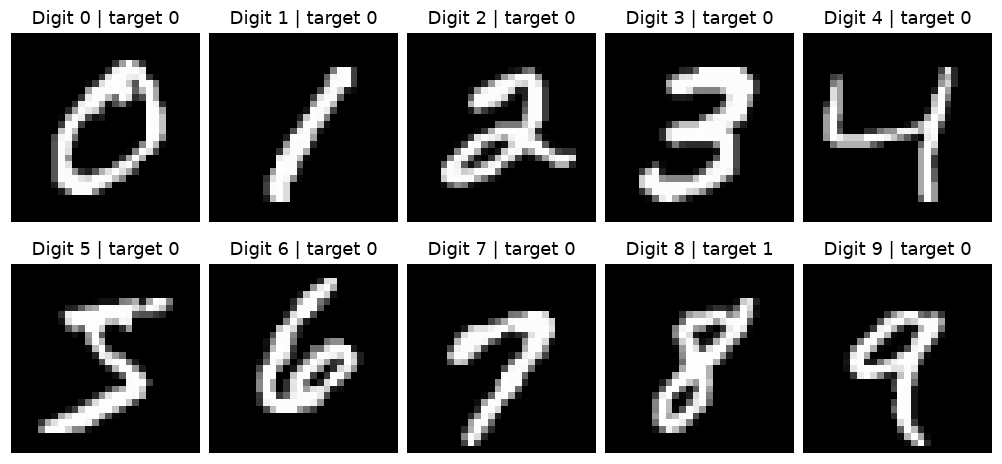

Training: 50000 | Validation: 10000 | Test: 10000


In [2]:
# @title Find local MNIST files, or download them in Colab
# Both "minst" (the repository folder) and "mnist" are supported.
DATA_FOLDER = Path('minst')
DATA_FOLDER.mkdir(exist_ok=True)

def load_idx(stem, dimensions):
    dotted = stem.replace('-idx', '.idx')
    candidates = []
    for folder in [DATA_FOLDER, Path('mnist'), Path('data/MNIST/raw'), Path('.')]:
        for name in [stem, dotted, stem + '.gz', dotted + '.gz']:
            candidates.extend([folder / name, folder / stem / name])
    path = next((p for p in candidates if p.is_file()), None)
    if path is None:
        path = DATA_FOLDER / (stem + '.gz')
        url = 'https://storage.googleapis.com/cvdf-datasets/mnist/' + stem + '.gz'
        temporary = path.with_suffix('.download')
        print('Downloading', stem)
        try:
            with urllib.request.urlopen(url, timeout=120) as response:
                temporary.write_bytes(response.read())
            temporary.replace(path)
        except Exception as error:
            temporary.unlink(missing_ok=True)
            raise RuntimeError('MNIST download failed. Retry, or upload the four IDX files into a minst folder.') from error
    raw = gzip.open(path, 'rb').read() if path.suffix == '.gz' else path.read_bytes()
    expected_magic = 2051 if dimensions == 3 else 2049
    magic = struct.unpack('>I', raw[:4])[0]
    if magic != expected_magic:
        raise ValueError(f'Unexpected IDX header in {path}')
    shape = struct.unpack('>' + 'I' * dimensions, raw[4:4 + 4 * dimensions])
    values = np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * dimensions).copy()
    if values.size != np.prod(shape):
        raise ValueError(f'Incomplete IDX data in {path}')
    return values.reshape(shape)

train_images = load_idx('train-images-idx3-ubyte', 3)
train_digits = load_idx('train-labels-idx1-ubyte', 1)
test_images = load_idx('t10k-images-idx3-ubyte', 3)
test_digits = load_idx('t10k-labels-idx1-ubyte', 1)
assert train_images.shape == (60000, 28, 28) and test_images.shape == (10000, 28, 28)
assert train_digits.shape == (60000,) and test_digits.shape == (10000,)
assert train_digits.max() <= 9 and test_digits.max() <= 9

all_x = torch.from_numpy(train_images).float().reshape(-1, 784) / 255
all_y = torch.from_numpy((train_digits == 8).astype(np.float32))
order = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED))
train_ids, val_ids = order[:50000], order[50000:]
x_train, y_train = all_x[train_ids], all_y[train_ids]
x_val, y_val = all_x[val_ids], all_y[val_ids]
val_digits = train_digits[val_ids.numpy()]
x_test = torch.from_numpy(test_images).float().reshape(-1, 784) / 255
y_test = torch.from_numpy((test_digits == 8).astype(np.float32))

fig, axes = plt.subplots(2, 5, figsize=(9, 4.2), layout='constrained')
for digit, ax in enumerate(axes.flat):
    example = train_images[np.flatnonzero(train_digits == digit)[0]]
    ax.imshow(example, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit} | target {int(digit == 8)}')
    ax.axis('off')
plt.show()
print('Training:', len(x_train), '| Validation:', len(x_val), '| Test:', len(x_test))

## 2. Build and train the network
Each hidden neuron is a logistic regression on the pixels. The output is a logistic regression on the four hidden values.

**Pixels → weighted sums + biases → four sigmoid values → weighted sum + bias → P(8)**

Training changes **weights and biases** while keeping the pictures fixed. We maximize the average log likelihood of the correct training answers, including both 8s and non-8s. This is the MLE idea from section and the uphill update from Week 3.

The code uses `Adam(..., maximize=True)` to take adaptive ascent steps. `binary_cross_entropy_with_logits` returns the **negative** average log likelihood; putting a minus sign in front gives the score we maximize. We use natural logs here; changing the log base would not change the best weights.

In [3]:
class SmallEightNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 4)
        self.output = nn.Linear(4, 1)
        # Start with two supporting and two opposing paths; all remain trainable.
        # This is an initialization choice, not a rule imposed after learning.
        with torch.no_grad():
            self.output.weight.copy_(torch.tensor([[1., 1., -1., -1.]]))
            fraction_eights = float(y_train.mean())
            self.output.bias.fill_(np.log(fraction_eights / (1 - fraction_eights)))

    def forward(self, pixels):
        hidden_values = torch.sigmoid(self.hidden(pixels))
        return self.output(hidden_values).squeeze(-1)  # Output before sigmoid: a logit.

    def inspect(self, pixels):
        hidden_totals = self.hidden(pixels)
        hidden_values = torch.sigmoid(hidden_totals)
        output_total = self.output(hidden_values).squeeze(-1)
        return hidden_totals, hidden_values, output_total, torch.sigmoid(output_total)

torch.manual_seed(SEED)
model = SmallEightNet().to(DEVICE)
initial_weights = model.hidden.weight.detach().clone()
initial_output_weights = model.output.weight.detach().clone()
initial_hidden_bias = model.hidden.bias.detach().clone()
initial_output_bias = model.output.bias.detach().clone()
print('Learned parameters:', sum(p.numel() for p in model.parameters()))

Learned parameters: 3145


Epoch  1: train LL -0.148 | validation LL -0.155
Epoch  2: train LL -0.123 | validation LL -0.133
Epoch  3: train LL -0.106 | validation LL -0.117
Epoch  4: train LL -0.093 | validation LL -0.103
Epoch  5: train LL -0.083 | validation LL -0.093
Epoch  6: train LL -0.075 | validation LL -0.086
Epoch  7: train LL -0.071 | validation LL -0.082
Epoch  8: train LL -0.064 | validation LL -0.077
Epoch  9: train LL -0.061 | validation LL -0.074
Epoch 10: train LL -0.058 | validation LL -0.072
Epoch 11: train LL -0.057 | validation LL -0.070
Epoch 12: train LL -0.054 | validation LL -0.069
Epoch 13: train LL -0.053 | validation LL -0.066
Epoch 14: train LL -0.051 | validation LL -0.066
Epoch 15: train LL -0.049 | validation LL -0.066
Epoch 16: train LL -0.050 | validation LL -0.069
Epoch 17: train LL -0.047 | validation LL -0.065
Epoch 18: train LL -0.046 | validation LL -0.064
Epoch 19: train LL -0.045 | validation LL -0.065
Epoch 20: train LL -0.044 | validation LL -0.063
Training finished in

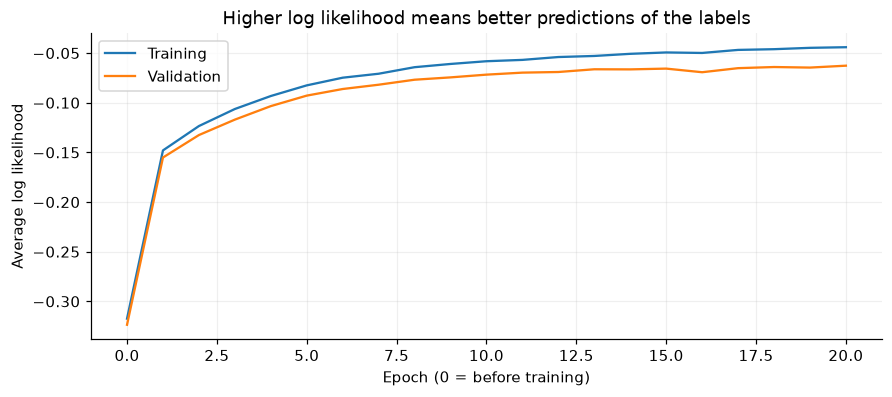

Test accuracy: 98.4%
Always saying "not 8" would score: 90.3%
Recall for real 8s: 89.4%
Precision when saying 8: 93.5%
Missed 8s: 103 | Non-8s incorrectly called 8: 61


In [4]:
# Rerunning this cell starts training afresh, rather than continuing an old run.
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.003
torch.manual_seed(SEED)
model = SmallEightNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, maximize=True)
history = []
start_time = time.perf_counter()

@torch.no_grad()
def evaluate(pixels, targets):
    logits = model(pixels)
    ll = -F.binary_cross_entropy_with_logits(logits, targets).item()
    accuracy = ((logits >= 0) == targets.bool()).float().mean().item()
    return ll, accuracy

history.append((*evaluate(x_train, y_train), *evaluate(x_val, y_val)))
for epoch in range(EPOCHS):
    model.train()
    shuffled = torch.randperm(len(x_train))
    for batch in shuffled.split(BATCH_SIZE):
        optimizer.zero_grad()
        logits = model(x_train[batch])
        log_likelihood = -F.binary_cross_entropy_with_logits(logits, y_train[batch])
        log_likelihood.backward()
        optimizer.step()
    model.eval()
    history.append((*evaluate(x_train, y_train), *evaluate(x_val, y_val)))
    print(f'Epoch {epoch+1:2d}: train LL {history[-1][0]:.3f} | validation LL {history[-1][2]:.3f}')

# Freeze learned parameters. Later gradients will be with respect to pixels only.
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)
print(f'Training finished in {time.perf_counter()-start_time:.0f} seconds.')

fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
ax.plot(np.array(history)[:, 0], label='Training')
ax.plot(np.array(history)[:, 2], label='Validation')
ax.set(xlabel='Epoch (0 = before training)', ylabel='Average log likelihood',
       title='Higher log likelihood means better predictions of the labels')
ax.legend(); ax.grid(alpha=.2)
plt.show()

with torch.no_grad():
    test_probs = torch.sigmoid(model(x_test))
predicted_eight = test_probs >= .5
is_eight = y_test.bool()
tp = int((predicted_eight & is_eight).sum())
tn = int((~predicted_eight & ~is_eight).sum())
fp = int((predicted_eight & ~is_eight).sum())
fn = int((~predicted_eight & is_eight).sum())
print(f'Test accuracy: {(tp+tn)/len(y_test):.1%}')
print(f'Always saying "not 8" would score: {float((~is_eight).float().mean()):.1%}')
print(f'Recall for real 8s: {tp/(tp+fn):.1%}')
print(f'Precision when saying 8: {tp/max(tp+fp, 1):.1%}')
print(f'Missed 8s: {fn} | Non-8s incorrectly called 8: {fp}')

Accuracy alone can be misleading: most pictures are not 8s. **Recall** asks how many real 8s we find; **precision** asks how often an “8” prediction is correct.

The validation curve shows performance on examples that did not update the weights. We use a fixed training duration, not the test set to choose an epoch. A fixed seed makes reruns more repeatable, but software versions can still change the results slightly.

For this small sigmoid network, we initialize two output weights at +1 and two at −1, with the output bias based on the training fraction of 8s. This starts the overall predicted probability near that fraction rather than near 50%. **Those initial signs are a setup choice, not a discovery.** All weights and biases then learn freely; inspect their final values and responses rather than treating the neuron numbers as fixed meanings.

## 3. Hidden layer: what changed during learning?
Each hidden neuron learned **784 weights and one bias**. Reshape its weights into a 28 × 28 picture so every weight lines up with its input pixel.

- **Pink:** adding ink here raises this neuron's weighted sum.
- **Blue:** adding ink here lowers it.
- **White:** a weight near zero.

These are **weight maps, not pictures the neuron sees or produces**. All maps below share the same colour scale, centered on zero. The bias also matters, even though it is not a pixel in the map.
The initial random weights look faint on this shared scale because they are much smaller than the learned weights.

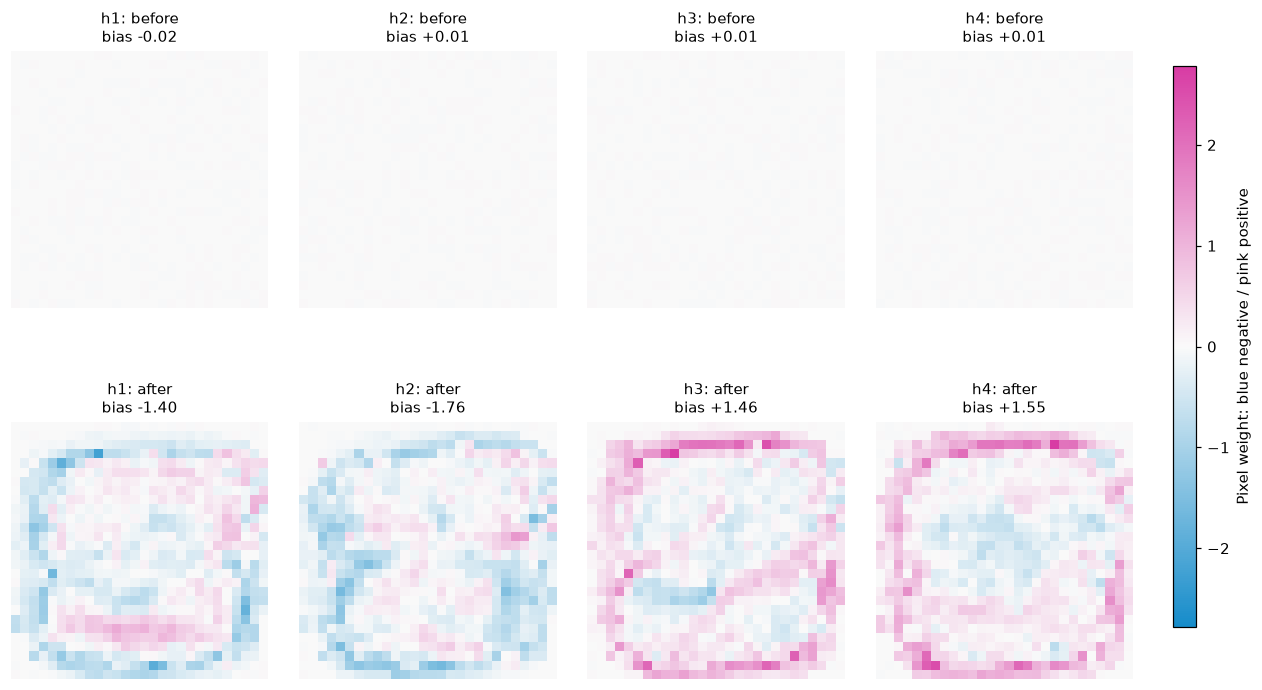

In [5]:
weights = model.hidden.weight.detach().numpy()
hidden_bias = model.hidden.bias.detach().numpy()
output_weights = model.output.weight.detach().numpy().ravel()
output_bias = float(model.output.bias.detach()[0])
scale = max(float(initial_weights.abs().max()), float(np.abs(weights).max()))
fig, axes = plt.subplots(2, 4, figsize=(12, 6.7))
fig.subplots_adjust(left=.02, right=.87, bottom=.03, top=.92, wspace=.12, hspace=.30)
for j in range(4):
    for row, values in enumerate([initial_weights.numpy(), weights]):
        im = axes[row, j].imshow(values[j].reshape(28, 28), cmap=signed_map, vmin=-scale, vmax=scale)
        bias = float(initial_hidden_bias[j]) if row == 0 else hidden_bias[j]
        axes[row, j].set_title(f'h{j+1}: {"before" if row == 0 else "after"}\nbias {bias:+.2f}', fontsize=10)
        axes[row, j].axis('off')
colour_axis = fig.add_axes([.90, .12, .018, .76])
fig.colorbar(im, cax=colour_axis, label='Pixel weight: blue negative / pink positive')
plt.show()

## 4. Follow one picture through every layer
Run the next cell, then change `example_index` to inspect another test picture. The initial choice is a correctly classified 8 with P(8) ≥ 0.8, if available. It is a demonstration example, not a random sample for measuring accuracy.

The four hidden activations are **numbers between 0 and 1**, not four miniature digit images. We mark 0.5 to match the section's “fires” language, but the output uses their full continuous values.

An output weight above zero means that increasing this hidden neuron raises P(8). A negative output weight means that increasing it lowers P(8): a **veto-like** role. These are influences, not an exact Boolean rule.

Suggested test example_index: 84


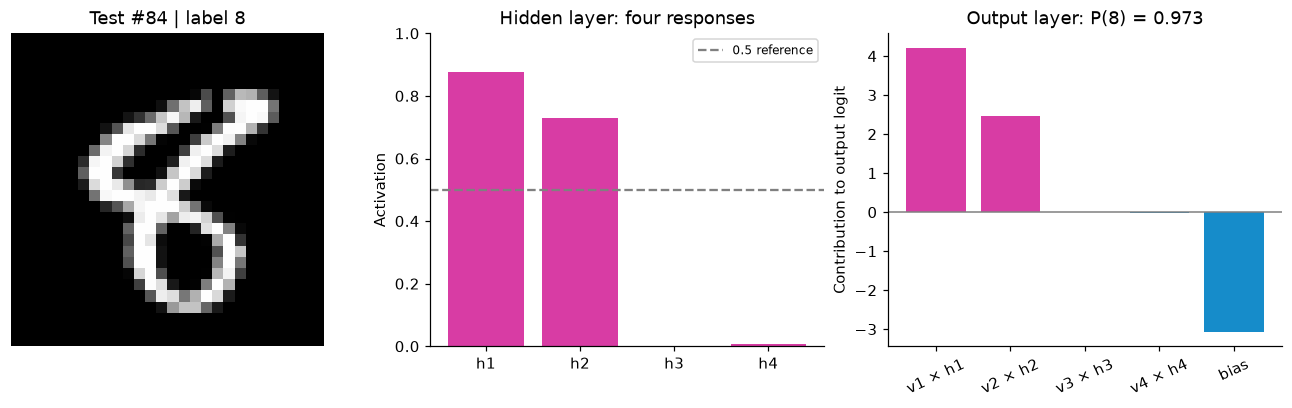

Neuron    total z    activation h    output weight v    contribution v*h
h1        +1.973       0.878             +4.804              +4.218
h2        +0.985       0.728             +3.394              +2.471
h3        -6.595       0.001             -5.627              -0.008
h4        -5.149       0.006             -5.774              -0.033
Output total = contributions + bias = +3.576
Sigmoid(output total) = 0.973; prediction: 8


In [6]:
eligible_eights = torch.where((y_test == 1) & (test_probs >= .8))[0]
if len(eligible_eights) == 0:
    eligible_eights = torch.where((y_test == 1) & (test_probs >= .5))[0]
if len(eligible_eights) == 0:
    raise RuntimeError('No correctly classified test 8 found. Check training before exploring attacks.')
DEFAULT_INDEX = int(eligible_eights[0])
print('Suggested test example_index:', DEFAULT_INDEX)

def inspect_picture(pixels, heading):
    with torch.no_grad():
        z, h, output_z, p = model.inspect(pixels)
    contributions = output_weights * h.numpy()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout='constrained')
    axes[0].imshow(pixels.numpy().reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    axes[0].set_title(heading); axes[0].axis('off')
    axes[1].bar(range(4), h.numpy(), color=PINK)
    axes[1].axhline(.5, ls='--', color='gray', label='0.5 reference')
    axes[1].set(xticks=range(4), xticklabels=['h1','h2','h3','h4'], ylim=(0,1),
                ylabel='Activation', title='Hidden layer: four responses')
    axes[1].legend(fontsize=8)
    terms = np.r_[contributions, output_bias]
    axes[2].bar(range(5), terms, color=[PINK if v >= 0 else BLUE for v in terms])
    axes[2].axhline(0, color='gray', lw=1)
    axes[2].set(xticks=range(5), xticklabels=['v1 × h1','v2 × h2','v3 × h3','v4 × h4','bias'],
                ylabel='Contribution to output logit', title=f'Output layer: P(8) = {float(p):.3f}')
    axes[2].tick_params(axis='x', labelrotation=25)
    plt.show()
    print('Neuron    total z    activation h    output weight v    contribution v*h')
    for j in range(4):
        print(f'h{j+1}       {float(z[j]):+7.3f}       {float(h[j]):.3f}            {output_weights[j]:+7.3f}             {contributions[j]:+7.3f}')
    print(f'Output total = contributions + bias = {float(output_z):+.3f}')
    print(f'Sigmoid(output total) = {float(p):.3f}; prediction: {"8" if p >= .5 else "not 8"}')
    return h.numpy(), float(p)

# Change this to any integer from 0 to 9999, then rerun this cell.
example_index = DEFAULT_INDEX
if not 0 <= example_index < len(x_test):
    raise ValueError('example_index must be between 0 and 9999.')
example_h, example_p = inspect_picture(x_test[example_index], f'Test #{example_index} | label {test_digits[example_index]}')

## 5. Which real pictures make each neuron respond?
A weight map shows the direction of each pixel's influence. To understand the responses, also look at **real examples that strongly activate the neuron**.

Below are the six strongest responses for each hidden neuron among the 10,000 validation pictures. A high response does not necessarily mean “8”: a neuron with a negative output weight may respond strongly to non-8 patterns.

Look for similarities, but avoid assigning a firm name such as “loop detector” from a few pictures. The model was trained to predict labels, not to give each neuron a human-readable job.

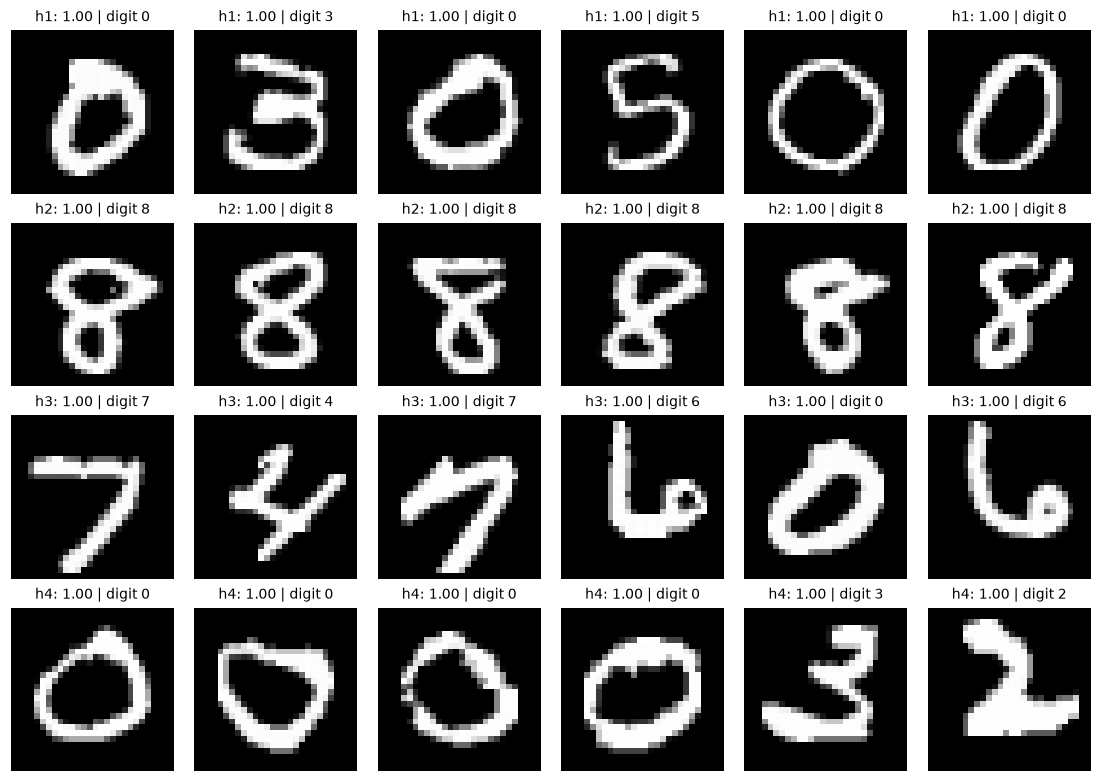

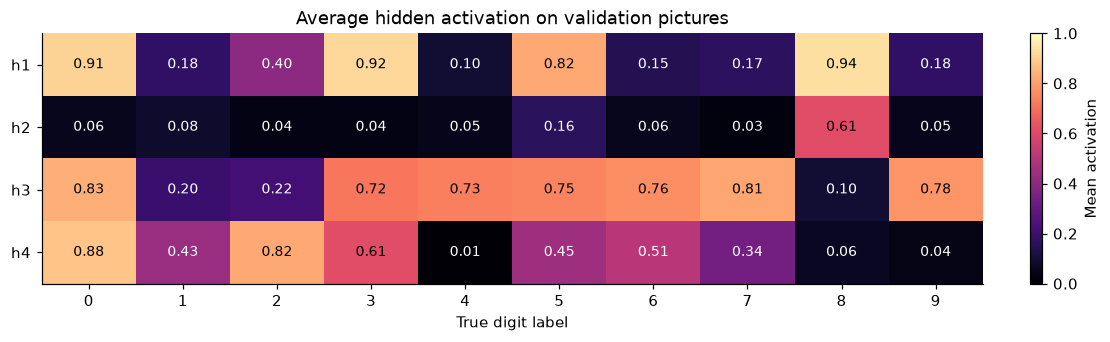

In [7]:
with torch.no_grad():
    _, validation_h, _, _ = model.inspect(x_val)
fig, axes = plt.subplots(4, 6, figsize=(10, 7), layout='constrained')
for j in range(4):
    best = torch.topk(validation_h[:, j], 6).indices
    for column, index in enumerate(best):
        ax = axes[j, column]
        ax.imshow(x_val[index].numpy().reshape(28,28), cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'h{j+1}: {float(validation_h[index,j]):.2f} | digit {val_digits[index]}', fontsize=9)
        ax.axis('off')
plt.show()

mean_response = np.stack([validation_h[val_digits == digit].mean(0).numpy() for digit in range(10)], axis=1)
fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
im = ax.imshow(mean_response, vmin=0, vmax=1, cmap='magma', aspect='auto')
ax.set(xticks=range(10), yticks=range(4), yticklabels=['h1','h2','h3','h4'],
       xlabel='True digit label', title='Average hidden activation on validation pictures')
for j in range(4):
    for digit in range(10):
        ax.text(digit, j, f'{mean_response[j,digit]:.2f}', ha='center', va='center',
                color='black' if mean_response[j,digit] > .6 else 'white', fontsize=9)
fig.colorbar(im, ax=ax, label='Mean activation')
plt.show()

## 6. Output layer: which responses support or oppose “8”?
The output layer learned four weights and a bias. Unlike the first layer, it does **not** have 784 pixel weights, so reshaping it into a digit image would be misleading.

Compare the output's weights before and after training. Their signs tell us whether a hidden response supports or opposes “8,” **holding the other responses fixed**. Their magnitudes describe changes in the output's weighted total (logit), not percentage-point changes in probability.

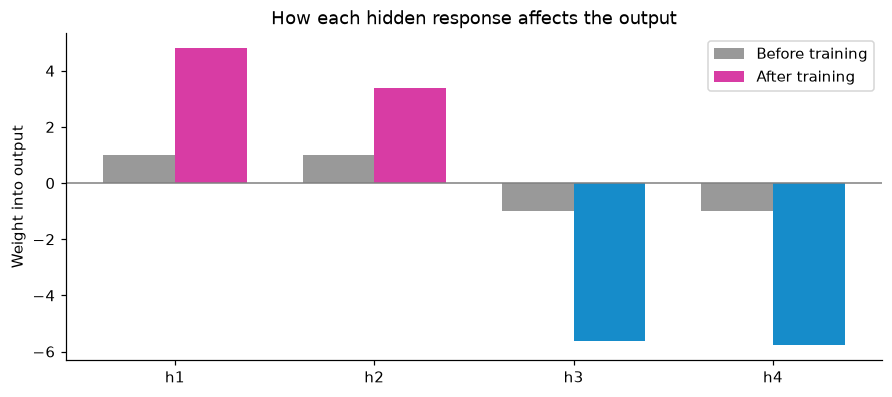

h1: +4.804 — increasing this response raises P(8)
h2: +3.394 — increasing this response raises P(8)
h3: -5.627 — increasing this response lowers P(8)
h4: -5.774 — increasing this response lowers P(8)
Output bias: before -2.230; after -3.073


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
locations = np.arange(4)
ax.bar(locations-.18, initial_output_weights.numpy().ravel(), width=.36, color='#999999', label='Before training')
ax.bar(locations+.18, output_weights, width=.36, color=[PINK if w >= 0 else BLUE for w in output_weights], label='After training')
ax.axhline(0, color='gray', lw=1)
ax.set(xticks=locations, xticklabels=['h1','h2','h3','h4'], ylabel='Weight into output', title='How each hidden response affects the output')
ax.legend(); plt.show()
for j, weight in enumerate(output_weights):
    print(f'h{j+1}: {weight:+.3f} — increasing this response {"raises" if weight >= 0 else "lowers"} P(8)')
print(f'Output bias: before {float(initial_output_bias[0]):+.3f}; after {output_bias:+.3f}')

## 7. Why can a few pixels change the answer?
For the next experiments we return to the suggested correctly classified 8. All three strategies start from **the same picture** and may only turn **exactly black pixels (0) fully white (1)**. Existing gray and white pixels stay unchanged.

First compare a hidden neuron's weights with the slope of **log P(8)** with respect to each input pixel. We select a hidden neuron with a strongly negative output weight when one exists.

**The colours refer to different quantities:**
- In the weight map, pink raises the selected hidden neuron.
- In the slope map, blue lowers log P(8), and therefore lowers P(8), for a small increase in pixel brightness.

The slope adds all four paths through the hidden layer. A local slope is not an exact prediction of what a full black-to-white jump will do.

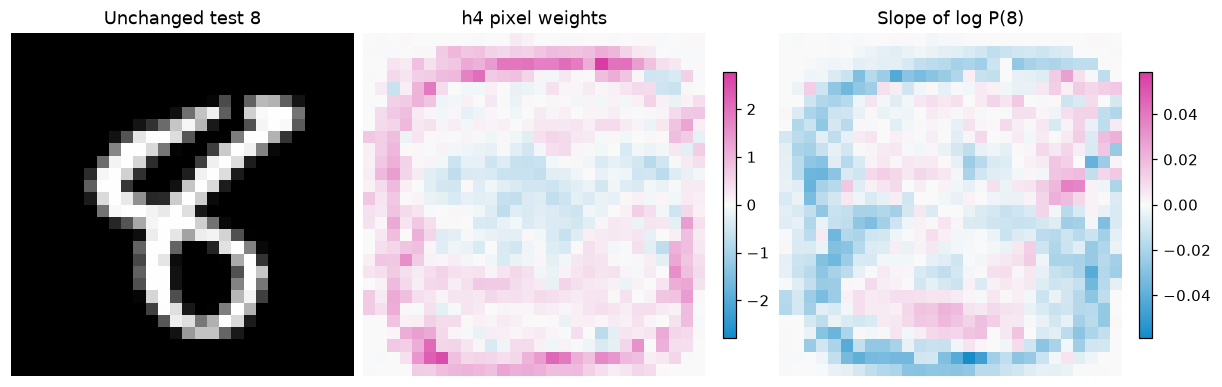

Selected h4; output weight -5.774
Colour scales differ between weight and slope maps; compare signs and patterns.


In [9]:
clean = x_test[DEFAULT_INDEX].clone()
negative_neurons = np.flatnonzero(output_weights < 0)
target_neuron = int(negative_neurons[np.argmin(output_weights[negative_neurons])]) if len(negative_neurons) else int(np.argmax(output_weights))

def pixel_slopes(pixels):
    variable_pixels = pixels.detach().clone().requires_grad_(True)
    log_p8 = F.logsigmoid(model(variable_pixels))
    return torch.autograd.grad(log_p8, variable_pixels)[0].detach()

gradient = pixel_slopes(clean)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout='constrained')
axes[0].imshow(clean.numpy().reshape(28,28), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Unchanged test 8')
for ax, values, title in [(axes[1], weights[target_neuron], f'h{target_neuron+1} pixel weights'),
                           (axes[2], gradient.numpy(), 'Slope of log P(8)')]:
    limit = max(float(np.abs(values).max()), 1e-8)
    im = ax.imshow(values.reshape(28,28), cmap=signed_map, vmin=-limit, vmax=limit)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=.65)
for ax in axes: ax.axis('off')
plt.show()
print(f'Selected h{target_neuron+1}; output weight {output_weights[target_neuron]:+.3f}')
print('Colour scales differ between weight and slope maps; compare signs and patterns.')

## 8. Compare the section's three strategies
1. **Try every remaining blank pixel:** evaluate every candidate and keep the one giving the lowest P(8). Repeat. This is a greedy search, not an exhaustive search over every possible combination of pixels.
2. **Read one neuron's weights:** for a negative output weight, ink that neuron's most positive pixel weights first. If every output weight is positive, instead use negative pixel weights to reduce a supporting neuron's response. This ranking ignores the other hidden neurons.
3. **Follow the slope:** ink the blank pixel with the most negative slope of log P(8), then recalculate the slopes.

We stop when **P(8) < 0.5**, or after 40 additions. A failed attempt is reported rather than treated as a flip. **None of these searches proves that its pixel count is the smallest possible for this new model.**

The candidate counts below count separate candidate pictures, even when PyTorch evaluates many in a single batch. Weight inspection needs no trial candidates, but we still evaluate the chosen pictures to know when to stop.

Strategy             Added    Final P(8)   Flipped?   Candidate trials   Backward passes
Try every pixel        2       0.021       True        1199                0
Read one neuron        2       0.049       True           0                0
Follow the slope       2       0.021       True           0                2


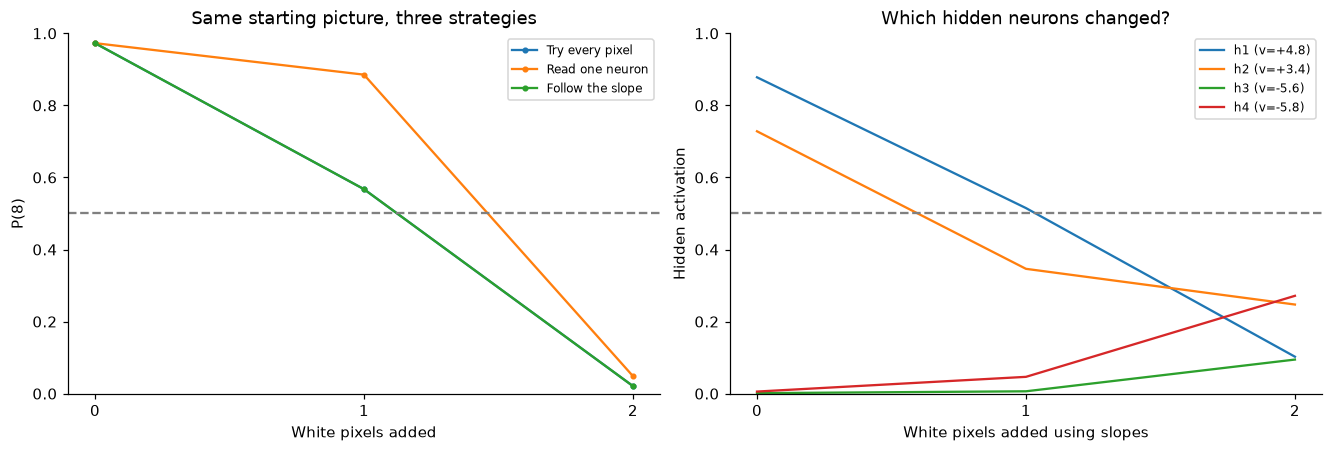

In [10]:
MAX_ADDITIONS = 40

def attack(method, original, max_additions=MAX_ADDITIONS):
    picture = original.clone()
    changed, probabilities, responses = [], [], []
    trials, backward_passes = 0, 0
    for step in range(max_additions + 1):
        with torch.no_grad():
            _, h, _, probability = model.inspect(picture)
        probabilities.append(float(probability)); responses.append(h.numpy())
        if probability < .5 or step == max_additions:
            break
        blank = torch.where(picture == 0)[0]
        if len(blank) == 0:
            break
        if method == 'Try every pixel':
            candidates = picture.repeat(len(blank), 1)
            candidates[torch.arange(len(blank)), blank] = 1
            with torch.no_grad():
                candidate_probs = torch.sigmoid(model(candidates))
            chosen = int(blank[candidate_probs.argmin()])
            trials += len(blank)
        elif method == 'Read one neuron':
            # Minimize this neuron's estimated contribution to the output total.
            influence = output_weights[target_neuron] * weights[target_neuron, blank.numpy()]
            chosen = int(blank[int(np.argmin(influence))])
        elif method == 'Follow the slope':
            slope = pixel_slopes(picture)
            chosen = int(blank[slope[blank].argmin()])
            backward_passes += 1
        else:
            raise ValueError(method)
        picture[chosen] = 1
        changed.append(chosen)
    return {'picture': picture, 'changed': changed, 'p': np.array(probabilities),
            'h': np.array(responses), 'trials': trials, 'backward': backward_passes,
            'flipped': probabilities[-1] < .5}

results = {method: attack(method, clean) for method in ['Try every pixel','Read one neuron','Follow the slope']}
print('Strategy             Added    Final P(8)   Flipped?   Candidate trials   Backward passes')
for method, result in results.items():
    print(f'{method:20s} {len(result["changed"]):3d}       {result["p"][-1]:.3f}       {str(result["flipped"]):5s}      {result["trials"]:5d}              {result["backward"]:3d}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for method, result in results.items():
    axes[0].plot(range(len(result['p'])), result['p'], marker='.', label=method)
axes[0].axhline(.5, color='gray', ls='--')
axes[0].set(xlabel='White pixels added', ylabel='P(8)', ylim=(0,1), title='Same starting picture, three strategies')
axes[0].legend(fontsize=8)
slope_result = results['Follow the slope']
for j in range(4):
    axes[1].plot(slope_result['h'][:,j], label=f'h{j+1} (v={output_weights[j]:+.1f})')
axes[1].axhline(.5, color='gray', ls='--')
axes[1].set(xlabel='White pixels added using slopes', ylabel='Hidden activation', ylim=(0,1), title='Which hidden neurons changed?')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

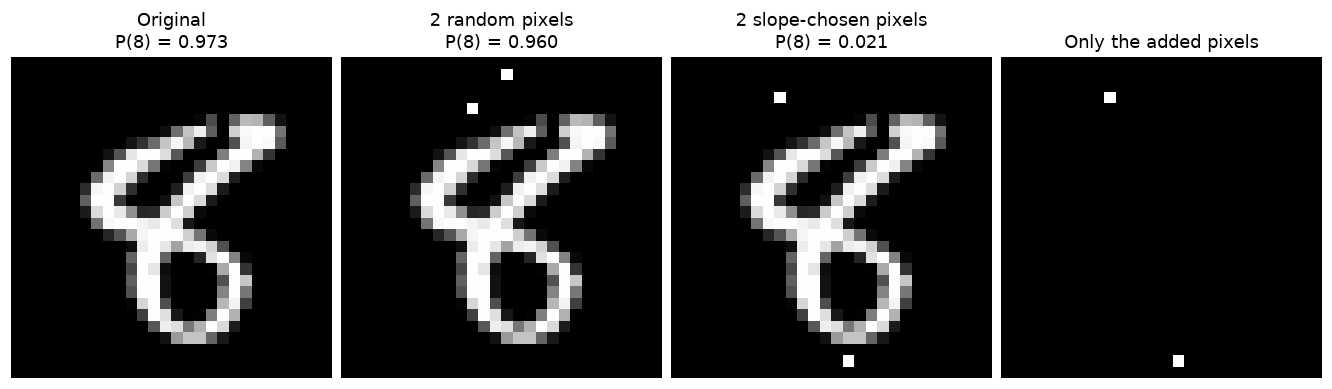

This is one random comparison, not a guarantee that random pixels are harmless.


In [11]:
# Compare chosen pixels with the SAME NUMBER of random blank pixels.
added_count = len(slope_result['changed'])
random_picture = clean.clone()
blank = torch.where(clean == 0)[0]
random_order = torch.randperm(len(blank), generator=torch.Generator().manual_seed(SEED + 1))
random_picture[blank[random_order[:added_count]]] = 1
added_mask = (slope_result['picture'] - clean).numpy().reshape(28,28)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout='constrained')
for ax, pixels, title in [(axes[0], clean, 'Original'),
                          (axes[1], random_picture, f'{added_count} random pixels'),
                          (axes[2], slope_result['picture'], f'{added_count} slope-chosen pixels')]:
    with torch.no_grad(): p = float(torch.sigmoid(model(pixels)))
    ax.imshow(pixels.numpy().reshape(28,28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{title}\nP(8) = {p:.3f}')
axes[3].imshow(added_mask, cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Only the added pixels')
for ax in axes: ax.axis('off')
plt.show()
print('This is one random comparison, not a guarantee that random pixels are harmless.')

## 9. Optional exploration: what picture raises its “8” score?
Start from a black picture and change **all pixels** to increase log P(8). Unlike the previous attacks, pixels may become brighter or darker at each step; we keep values between 0 and 1.

The weights stay frozen. We are optimizing an input, not training the network. A high score means this picture satisfies the model's learned calculation; it does not mean a person would recognize an 8, or that the picture is representative of MNIST.

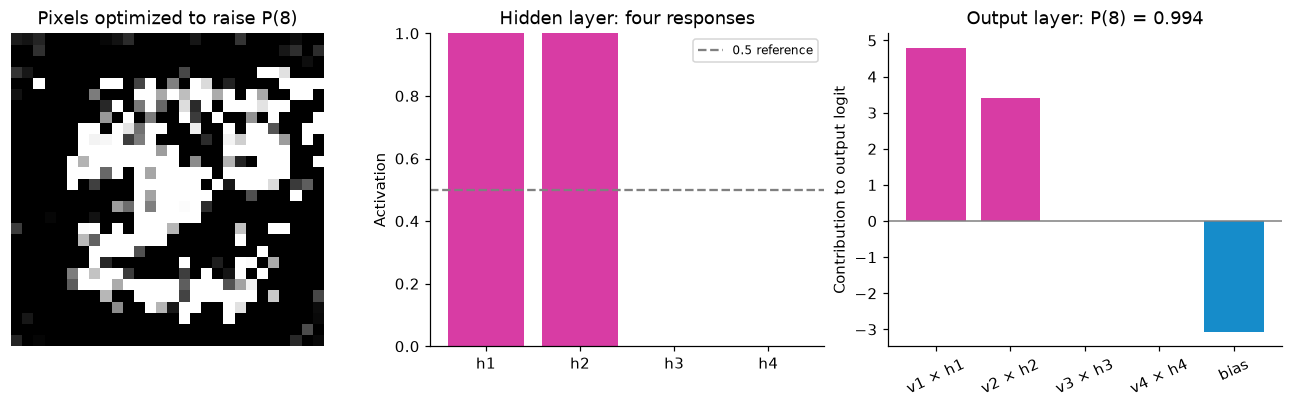

Neuron    total z    activation h    output weight v    contribution v*h
h1       +46.784       1.000             +4.804              +4.804
h2       +16.465       1.000             +3.394              +3.394
h3       -32.031       0.000             -5.627              -0.000
h4       -31.726       0.000             -5.774              -0.000
Output total = contributions + bias = +5.126
Sigmoid(output total) = 0.994; prediction: 8
Did the resulting pattern look like an 8 to you?


In [12]:
imagined = torch.zeros(784)
synthesis_scores = []
for step in range(100):
    gradient = pixel_slopes(imagined)
    imagined = (imagined + 5.0 * gradient).clamp(0, 1).detach()
    with torch.no_grad(): synthesis_scores.append(float(torch.sigmoid(model(imagined))))
imagined_h, imagined_p = inspect_picture(imagined, 'Pixels optimized to raise P(8)')
print('Did the resulting pattern look like an 8 to you?')

## What can we say the layers learned?
- The **hidden layer** learned four weighted combinations of the 784 pixels. Its weight maps show signed pixel influences; its activations and strongly activating examples show how those combinations respond to real digits.
- The **output layer** learned how to combine those four responses into an “8” probability. Its weights identify supporting and opposing influences, and its bias shifts the overall decision.
- The **pixel gradient** explains how the current answer responds locally to each pixel. It depends on both layers and on the particular input; it is not another learned weight map.

This is a fully connected network. There are no convolutional feature maps here, and we should not assume an “edges → shapes → objects” hierarchy. The pictures provide evidence about behavior, not a complete explanation of everything the model has learned.

### Try one change
Choose a different `example_index` in section 4 and rerun that cell. Which hidden responses change? Can you use the output weights to explain the new answer?

To train a different model, change `SEED` in setup and rerun the whole notebook. Neuron numbers are not fixed meanings: h₁ in one trained model need not have the same role as h₁ in another.

### Training and input changes use the same machinery
| What changes? | What stays fixed? | What is the objective? |
|---|---|---|
| Training weights and biases | Training pictures and labels | Raise the log likelihood of correct labels |
| Adding adversarial white pixels | All learned weights and biases | Lower log P(8), subject to the allowed pixel edits |
| Synthesizing an input | All learned weights and biases | Raise log P(8), keeping pixels between 0 and 1 |

### Sources
Based on the supplied Section 5 materials, *The Mystery 8*.
- [MNIST dataset description](https://yann.lecun.com/exdb/mnist/)
- [MNIST download mirror used by this notebook](https://storage.googleapis.com/cvdf-datasets/mnist/)
- [PyTorch: automatic differentiation](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)

The original section's exact pixel counts and neuron weights belong to its trained model. This notebook reports the measurements of the model trained here.